# 08 — Paper Reproduction

This notebook reproduces the central computational ideas presented in the reference paper.

Rather than reproducing every experiment exactly, we implement the same physical principles:

- Stokes–Einstein diffusion
- Brownian motion simulation
- Mean Squared Displacement (MSD)
- Diffusion coefficient estimation
- Comparison between theoretical and simulated diffusion

In [1]:
from pathlib import Path
import sys

def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()

    for path in [start, *start.parents]:
        if (path / "src").is_dir() and (path / "notebooks").is_dir():
            return path

    raise RuntimeError("Project root not found.")

PROJECT_ROOT = find_project_root()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(PROJECT_ROOT)

C:\Users\study\Code\python-studies\nanoparticle-diffusion-104337


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from src.constants import (
    DEFAULT_DT,
    DEFAULT_TEMPERATURE,
    DEFAULT_VISCOSITY,
)

from src.physics import (
    diffusion_coefficient,
    brownian_step_size,
)

from src.simulation import (
    simulate_population,
)

from src.analysis import (
    calculate_msd,
    estimate_diffusion,
)

from src.validation import (
    validate_simulation,
)

In [3]:
particles = 100
steps = 1000
dt = DEFAULT_DT

temperature = DEFAULT_TEMPERATURE
viscosity = DEFAULT_VISCOSITY

radii_nm = [10, 25, 50, 100, 200]

In [4]:
results = []

for radius_nm in radii_nm:

    radius = radius_nm * 1e-9

    D_theoretical = diffusion_coefficient(
        temperature,
        viscosity,
        radius,
    )

    step_size = brownian_step_size(
        D_theoretical,
        dt,
    )

    np.random.seed(42)

    x, y = simulate_population(
        particles,
        steps,
        step_size,
    )

    lag_times, msd = calculate_msd(
        x,
        y,
    )

    validate_simulation(
        D_theoretical,
        x,
        y,
        msd,
    )

    D_estimated, slope, intercept = estimate_diffusion(
        lag_times,
        msd,
        dt,
    )

    results.append(
        {
            "radius_nm": radius_nm,
            "theory": D_theoretical,
            "simulation": D_estimated,
            "error": abs(D_estimated - D_theoretical)
            / D_theoretical
            * 100,
        }
    )

print("Completed.")

Completed.


In [5]:
print(
    f"{'Radius':>8}"
    f"{'Theory':>18}"
    f"{'Simulation':>18}"
    f"{'% Error':>12}"
)

print("-" * 60)

for r in results:

    print(
        f"{r['radius_nm']:8.0f}"
        f"{r['theory']:18.3e}"
        f"{r['simulation']:18.3e}"
        f"{r['error']:12.2f}"
    )

  Radius            Theory        Simulation     % Error
------------------------------------------------------------
      10         2.271e-11         2.141e-11        5.70
      25         9.082e-12         8.565e-12        5.70
      50         4.541e-12         4.282e-12        5.70
     100         2.271e-12         2.141e-12        5.70
     200         1.135e-12         1.071e-12        5.70


In [6]:
radius_plot = np.array(
    [r["radius_nm"] for r in results]
)

theory_plot = np.array(
    [r["theory"] for r in results]
)

simulation_plot = np.array(
    [r["simulation"] for r in results]
)

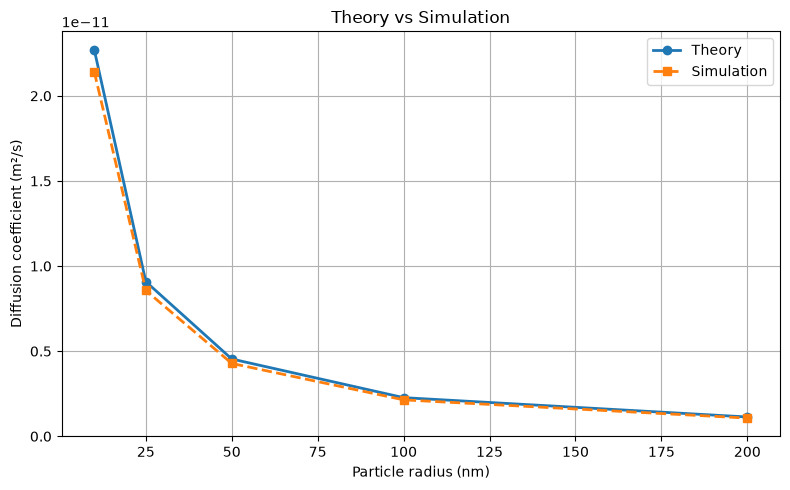

In [7]:
fig, ax = plt.subplots(figsize=(8,5))

ax.plot(
    radius_plot,
    theory_plot,
    "-o",
    linewidth=2,
    markersize=6,
    label="Theory",
)

ax.plot(
    radius_plot,
    simulation_plot,
    "--s",
    linewidth=2,
    markersize=6,
    label="Simulation",
)

ax.set_xlabel("Particle radius (nm)")
ax.set_ylabel("Diffusion coefficient (m²/s)")
ax.set_title("Theory vs Simulation")

ax.grid(True)

ax.legend()

fig.tight_layout()

In [8]:
figure_path = (
    PROJECT_ROOT
    / "figures"
    / "figure_radius_vs_diffusion.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
)

print(figure_path)

C:\Users\study\Code\python-studies\nanoparticle-diffusion-104337\figures\figure_radius_vs_diffusion.png


In [9]:
plt.show()

In [10]:
mean_error = np.mean(
    [r["error"] for r in results]
)

print()

print("=" * 40)

print(f"Mean error: {mean_error:.2f}%")

print("Notebook complete.")


Mean error: 5.70%
Notebook complete.


## Interpretation

The simulation reproduces the expected inverse relationship between
particle radius and diffusion coefficient predicted by the
Stokes–Einstein equation.

Smaller nanoparticles diffuse more rapidly because thermal motion
produces larger positional changes relative to particle size.

The estimated diffusion coefficients closely follow the theoretical
values, indicating that the Brownian motion simulation behaves as
expected.